# Food Delivery Time Prediction

Predicting how long a food delivery takes (in minutes) from courier, order, weather and traffic details.

**Data:** [Food Delivery Dataset on Kaggle](https://www.kaggle.com/datasets/gauravmalik26/food-delivery-dataset) — only `train.csv` is used, because Kaggle's `test.csv` has no target column. It is split 80/20 into training and test sets here.

The cleaning, feature engineering and model code live in the `delivery_time` package so that this notebook, `train.py` and `predict.py` all use exactly the same logic.

Contents:
1. Data quirks and cleaning
2. Feature engineering
3. Exploratory analysis
4. Modelling
5. Results on the test set
6. Residuals and feature importance

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

from delivery_time.features import (CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET,
                                    build_features, clean)
from delivery_time.modeling import (RANDOM_STATE, cross_val_rmse, evaluate,
                                    make_pipeline)

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")  # LightGBM feature-name notice
sns.set_theme(style="whitegrid", palette="deep")
pd.options.display.max_columns = None

## 1) Data quirks and cleaning

In [2]:
raw = pd.read_csv("data/train.csv")
print(raw.shape)
raw.head(3)

(45593, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26


The raw file needs some care before it is usable:

- Text values have trailing spaces (`"High "`), and missing values are stored as the **string** `"NaN"` rather than real nulls.
- The target is text like `"(min) 24"`, and weather values are prefixed with `"conditions "`.
- 53 rows have a courier rating of **6** on a 1–5 scale, which is invalid, so those ratings are treated as missing.
- Some coordinates have a flipped sign. Every order is in India, so all values should be positive, and `abs()` repairs them.
- About 8% of rows have restaurant coordinates near 0,0. Their delivery coordinates are offset from 0,0 in the same way, so the *distance* between the two points is still plausible and the rows are kept.

In [3]:
print("Missing values hidden as text:", (raw.astype(str).apply(lambda c: c.str.strip()) == "NaN").sum().sum())
print("Ratings above 5:", (pd.to_numeric(raw["Delivery_person_Ratings"], errors="coerce") > 5).sum())
print("Rows with a negative coordinate:", (raw.filter(like="itude") < 0).any(axis=1).sum())

Missing values hidden as text: 8515
Ratings above 5: 53
Rows with a negative coordinate: 431


In [4]:
data = clean(raw)
X = build_features(data)
y = data[TARGET]

X.isna().sum().to_frame("missing values").T

,courier_age,courier_rating,distance_km,order_hour,prep_min,vehicle_condition,multiple_deliveries,is_weekend,weather,traffic,order_type,vehicle_type,festival,city
missing values,1854,1961,0,0,1731,0,993,0,616,601,0,0,228,1200


Missing values are **not** filled in here. Imputation happens inside each model's pipeline, so the fill values are learned from the training set only and nothing from the test set leaks into training.

## 2) Feature engineering

`build_features` derives:

- `distance_km`: great-circle distance between the restaurant and the delivery location.
- `prep_min`: minutes between the order being placed and picked up (correct across midnight).
- `order_hour` and `is_weekend`.

Two features from the original version of this project were dropped: `year_quarter` has the same value in every row (all orders are from March 2022), and the pickup minute and hour duplicate information already in `order_hour` and `prep_min`.

In [5]:
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
courier_age,43739.0,29.57,5.82,15.00,25.00,30.00,35.00,50.00
courier_rating,43632.0,4.63,0.33,1.00,4.50,4.70,4.90,5.00
distance_km,45593.0,9.74,5.61,1.47,4.66,9.22,13.68,20.97
order_hour,45593.0,17.41,4.85,0.00,15.00,19.00,21.00,23.00
prep_min,43862.0,9.99,4.09,5.00,5.00,10.00,15.00,15.00
vehicle_condition,45593.0,1.02,0.84,0.00,0.00,1.00,2.00,3.00
multiple_deliveries,44600.0,0.74,0.57,0.00,0.00,1.00,1.00,3.00
is_weekend,45593.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00


## 3) Exploratory analysis

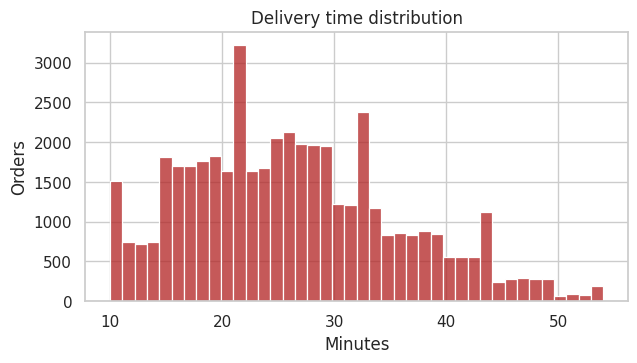

count    45593.0
mean        26.3
std          9.4
min         10.0
25%         19.0
50%         26.0
75%         32.0
max         54.0
Name: delivery_time_min, dtype: Float64


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(y, bins=40, ax=ax, color="firebrick")
ax.set(title="Delivery time distribution", xlabel="Minutes", ylabel="Orders")
plt.show()
print(y.describe().round(1))

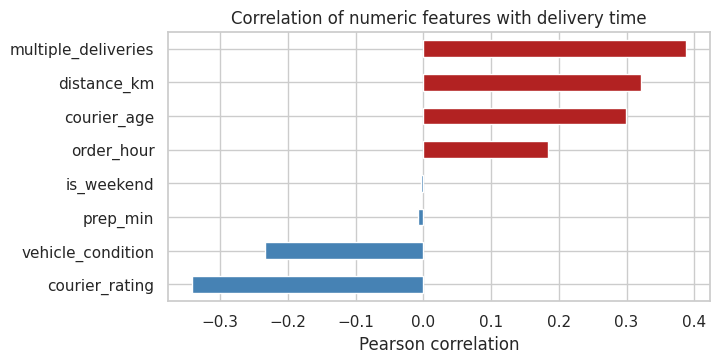

In [7]:
corr = pd.concat([X[NUMERIC_FEATURES], y], axis=1).corr()[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "firebrick", "steelblue"))
ax.set(title="Correlation of numeric features with delivery time", xlabel="Pearson correlation")
plt.show()

Orders carrying multiple deliveries, longer distances and older couriers go with longer delivery times, while higher courier ratings and better vehicle condition go with shorter ones. Preparation time and weekends show almost no linear relationship.

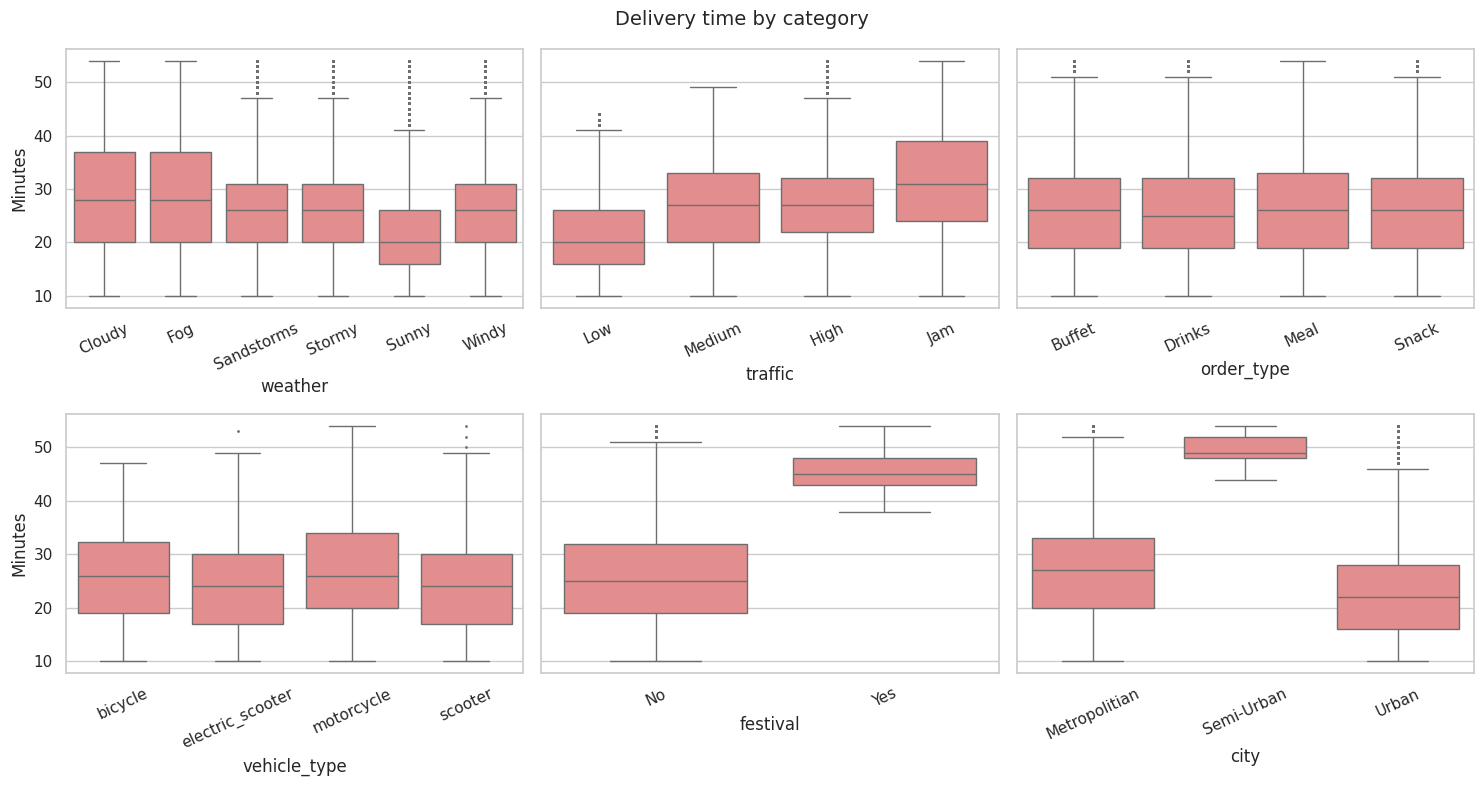

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, col in zip(axes.flat, CATEGORICAL_FEATURES):
    order = X.groupby(col)[col].size().index if col != "traffic" else ["Low", "Medium", "High", "Jam"]
    sns.boxplot(x=X[col], y=y, order=order, ax=ax, color="lightcoral", fliersize=1)
    ax.set(xlabel=col, ylabel="Minutes")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Delivery time by category", fontsize=14)
fig.tight_layout()
plt.show()

Several categories show large differences in average delivery time: traffic jams (31 min vs 21 in low traffic), fog and cloudy weather (29 min vs 22 when sunny), festival days (46 vs 26) and semi-urban areas (50 vs 23 in urban areas, though only 164 orders are semi-urban). Order type makes no visible difference.

## 4) Modelling

The data is split once, with a fixed seed, into 80% training and 20% test. The test set is used **only** for the final scores below — never for tuning, model selection or feature selection.

Models compared:
- **Linear Regression** (baseline, with one-hot encoding and scaling)
- **Random Forest**, **XGBoost** and **LightGBM** (ordinal encoding; traffic is encoded in its natural order Low < Medium < High < Jam)

Hyperparameters were chosen with randomized search and 3-fold cross-validation on the training set. That search is slow, so it lives in `train.py --tune`, which writes the chosen parameters to `params.json`. This notebook loads them.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training rows: {len(X_train)}, test rows: {len(X_test)}")

tuned = json.load(open("params.json"))
params, cv_rmse = tuned["params"], tuned["cv_rmse"]
cv_rmse["Linear Regression"] = cross_val_rmse(make_pipeline("Linear Regression"), X_train, y_train)

pd.DataFrame(params).T

Training rows: 36474, test rows: 9119


,n_estimators,max_depth,max_features,min_samples_leaf,colsample_bytree,learning_rate,min_child_weight,reg_lambda,subsample,min_child_samples,num_leaves,subsample_freq
Random Forest,200.0,NaN,0.5,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,500.0,9.0,NaN,NaN,0.908508,0.023718,9.0,6.759574,0.940015,NaN,NaN,NaN
LightGBM,500.0,NaN,NaN,NaN,0.890909,0.042420,NaN,1.100699,0.984469,23.0,101.0,1.0


In [10]:
models = ["Linear Regression", "Random Forest", "XGBoost", "LightGBM"]
fitted, rows = {}, []
for name in models:
    fitted[name] = make_pipeline(name, **params.get(name, {})).fit(X_train, y_train)
    rows.append({"model": name, "cv_rmse": cv_rmse[name], **evaluate(fitted[name], X_test, y_test)})

results = pd.DataFrame(rows).set_index("model")
best = results.drop("Linear Regression")["cv_rmse"].idxmin()  # selected by CV, not by test score
print("Selected model (lowest cross-validated RMSE):", best)
results.round(3)

Selected model (lowest cross-validated RMSE): XGBoost


,cv_rmse,rmse,mae,r2
model,,,,
Linear Regression,6.068,6.023,4.790,0.586
Random Forest,3.940,3.926,3.140,0.824
XGBoost,3.895,3.886,3.105,0.828
LightGBM,3.921,3.890,3.110,0.827


## 5) Results on the test set

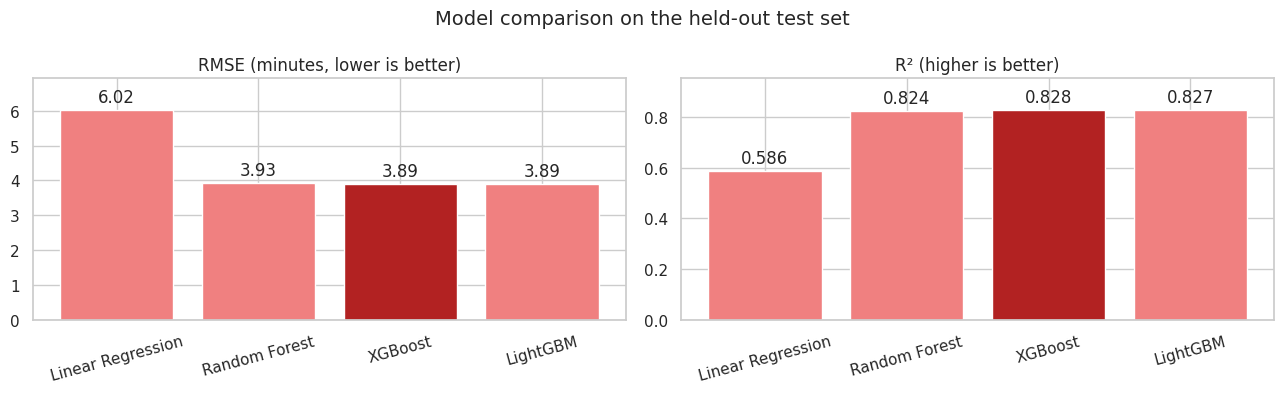

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, label in [(axes[0], "rmse", "RMSE (minutes, lower is better)"),
                          (axes[1], "r2", "R² (higher is better)")]:
    colors = ["firebrick" if m == best else "lightcoral" for m in results.index]
    bars = ax.bar(results.index, results[metric], color=colors)
    ax.bar_label(bars, fmt="%.2f" if metric == "rmse" else "%.3f", padding=3)
    ax.set(title=label, ylim=(0, results[metric].max() * 1.15))
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Model comparison on the held-out test set", fontsize=14)
fig.tight_layout()
fig.savefig("assets/model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## 6) Residuals and feature importance

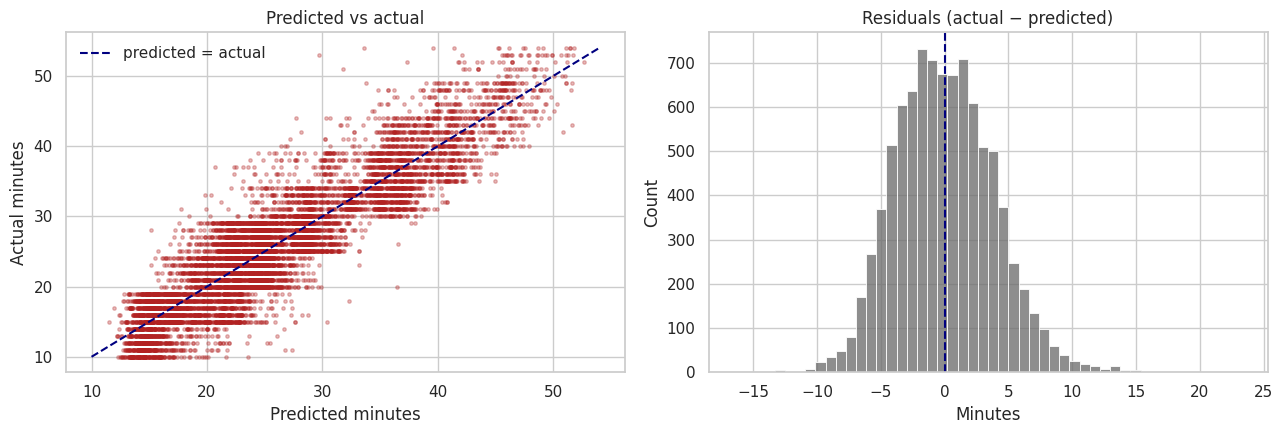

Mean residual: -0.01 min
Share of test orders predicted within 5 minutes: 82%


In [12]:
model = fitted[best]
pred = model.predict(X_test)
residuals = y_test - pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(pred, y_test, s=6, alpha=0.3, color="firebrick")
lims = [min(pred.min(), y_test.min()), max(pred.max(), y_test.max())]
axes[0].plot(lims, lims, "--", color="navy", label="predicted = actual")
axes[0].set(title="Predicted vs actual", xlabel="Predicted minutes", ylabel="Actual minutes")
axes[0].legend(frameon=False)

sns.histplot(residuals, bins=50, ax=axes[1], color="dimgray")
axes[1].axvline(0, ls="--", color="navy")
axes[1].set(title="Residuals (actual − predicted)", xlabel="Minutes")
fig.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.2f} min")
print(f"Share of test orders predicted within 5 minutes: {(residuals.abs() <= 5).mean():.0%}")

Feature importance is measured with **permutation importance**: how much the test RMSE gets worse when one feature's values are shuffled. Unlike built-in tree importances, it is measured in minutes, works the same way for any model and is not biased towards features with many distinct values. It is used here only to interpret the final model, not to choose features.

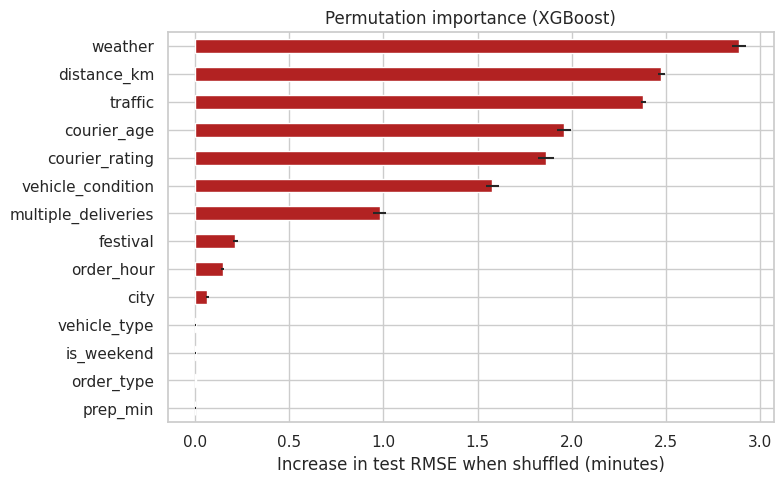

In [13]:
perm = permutation_importance(model, X_test, y_test, scoring="neg_root_mean_squared_error",
                              n_repeats=5, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot.barh(ax=ax, color="firebrick", xerr=perm.importances_std[importance.index.map(list(X_test.columns).index)])
ax.set(title=f"Permutation importance ({best})", xlabel="Increase in test RMSE when shuffled (minutes)")
fig.tight_layout()
fig.savefig("assets/feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

Weather, distance and traffic matter most, followed by the courier's age and rating and the vehicle's condition. Preparation time, order type, vehicle type and weekends contribute almost nothing.

## Summary

- The three tuned tree models perform almost identically, with test RMSE around 3.9 minutes and R² around 0.83. XGBoost has the lowest cross-validated error, so it is the model selected.
- Cross-validated and test scores agree closely, which suggests the evaluation is sound and the models are not overfitting.
- 82% of test orders are predicted within 5 minutes of the actual delivery time.

The selected pipeline is saved by `train.py` and used by `predict.py`. See the README for what changed from the original version of this notebook.